In [ ]:
from google.colab import files
uploaded = files.upload()

Saving lcparam_full_long.txt to lcparam_full_long.txt


WITHOUT MINIMIZNG CHI2

Enter value of n: 1


/tmp/ipython-input-1-1753185314.py:79: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ".k" (-> color='k'). The keyword argument will take precedence.
  plt.errorbar(z, dL_data / 1000, yerr=dmL_data / 1000, fmt='.k', color='black',ecolor='green', elinewidth=1, capsize=3, alpha=0.6)
/tmp/ipython-input-1-1753185314.py:83: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


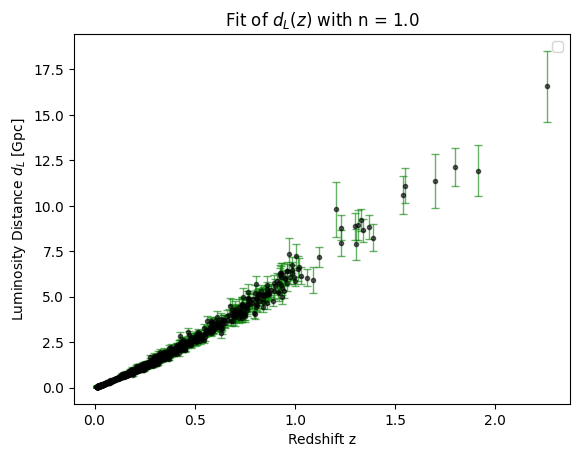

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import minimize
import time

# --- Load Data ---
df = pd.read_csv('lcparam_full_long.txt', sep=r'\s+', engine='python')
z = df['zcmb'].values
mb = df['mb'].values
dmu = df['dmb'].values  # Assumed to be the correct mu uncertainty column
M_B = -19.220
mu = mb - M_B

# Luminosity distance and error in Mpc
dL_data = 10 ** ((mu - 25) / 5)
dmL_data = np.log(10) * dL_data * dmu / 5

# --- Define Constants ---
C = 299792.458  # km/s
Or = 8.5e-5  # radiation density
ok=-0.053
# --- Model Functions ---
def H_integrand(z_, x, y, Ov, Ok, n):
    H0 = (x * y)**0.25
    Om = np.sqrt(y / x)
    On = 1 - Om - Ok - Ov - Or
    Ez2 = Or * (1 + z_)**4 + Om * (1 + z_)**3 + Ok * (1 + z_)**2 + On * (1 + z_)**n + Ov
    if Ez2 <= 0:
        return np.inf
    return 1 / (H0 * np.sqrt(Ez2))

def DL_theory_single(z, x, y, Ov, Ok, n):
    H0 = (x * y)**0.25
    try:
        integral, _ = quad(H_integrand, 0, z, args=(x, y, Ov, Ok, n), limit=200)
    except:
        return np.inf
    sqrtOk = np.sqrt(abs(Ok))
    if Ok > 0:
        return C * (1 + z) * np.sinh(H0 * sqrtOk * integral) / (H0 * sqrtOk)
    elif Ok < 0:
        return C * (1 + z) * np.sin(H0 * sqrtOk * integral) / (H0 * sqrtOk)
    else:
        return C * (1 + z) * integral

DL_theory_vec = np.vectorize(DL_theory_single, excluded=['x', 'y', 'Ov', 'Ok', 'n'])

# --- Chi-Squared ---
def log_posterior(theta, n):
    x, y, Ov = theta
    Ok = -0.053 # Use the fixed value of Ok
    if 8000 <= x <= 25000 and 0 <= Ov <= 1:
        xprior, Okprior, Ovprior=0,0,0
    else:
        xprior, Okprior, Ovprior=-np.inf,-np.inf,-np.inf
    H0 = (x * y)**0.25
    Om = np.sqrt(y / x)
    On = 1 - Om - Ok - Ov - Or
    if On < -1 or On >1:
        return -np.inf
    yprior = -((y - 1424.18)**2 / (2 * 31.37**2))
    priors=xprior+Okprior+Ovprior+yprior
    dL_model = DL_theory_vec(z=z, x=x, y=y,Ov=Ov, Ok=Ok, n=n)
    if np.any(np.isnan(dL_model)) or np.any(np.isinf(dL_model)):
        return -np.inf
    chi_sq = np.sum(((dL_data - dL_model) / dmL_data)**2)
    return -0.5*chi_sq + priors
def chi2(theta, n):
    x, y, Ov = theta
    Ok = -0.053 # Use the fixed value of Ok
    return -2*log_posterior(theta, n)
# --- Minimization ---
n_value = float(input("Enter value of n: "))
initial_guess = [19357, 1403.8, 0.594]  # from paper (for n=1)
# --- Plot Fit ---
#dL_model = DL_theory_vec(z=z, x=x, y=y, Ov=Ov, Ok=Ok, n=n_value)
plt.errorbar(z, dL_data / 1000, yerr=dmL_data / 1000, fmt='.k', color='black',ecolor='green', elinewidth=1, capsize=3, alpha=0.6)
#plt.plot(z, dL_model / 1000, 'r-', label="Best-Fit Model")
plt.xlabel("Redshift z")
plt.ylabel("Luminosity Distance $d_L$ [Gpc]")
plt.legend()
#plt.grid()
plt.title("Fit of $d_L(z)$ with n = {:.1f}".format(n_value))
plt.show()

In [ ]:
ndimension=3
no_of_walkers=20
no_of_steps_per_walker=15000
#burn_in_steps=500

initial_pos_of_walker = [initial_guess + 1e-3*np.random.randn(ndimension) for i in range(no_of_walkers)]
print(initial_pos_of_walker)

[array([1.93569997e+04, 1.40380208e+03, 5.93862696e-01]), array([1.93570011e+04, 1.40379988e+03, 5.94904728e-01]), array([1.93570009e+04, 1.40380099e+03, 5.92911446e-01]), array([1.93570002e+04, 1.40380208e+03, 5.94003387e-01]), array([1.93569983e+04, 1.40380067e+03, 5.94225199e-01]), array([1.93569997e+04, 1.40379969e+03, 5.92842731e-01]), array([1.93570009e+04, 1.40380002e+03, 5.95051709e-01]), array([1.93570000e+04, 1.40379740e+03, 5.94905751e-01]), array([1.93570017e+04, 1.40379897e+03, 5.93840365e-01]), array([1.93570004e+04, 1.40380054e+03, 5.93719670e-01]), array([1.93570003e+04, 1.40379967e+03, 5.91952306e-01]), array([1.93569996e+04, 1.40379840e+03, 5.94580865e-01]), array([1.93570001e+04, 1.40379985e+03, 5.93931386e-01]), array([1.93569993e+04, 1.40379826e+03, 5.95010363e-01]), array([1.93569991e+04, 1.40379912e+03, 5.94602909e-01]), array([1.93569993e+04, 1.40379886e+03, 5.92328358e-01]), array([1.93570008e+04, 1.40380116e+03, 5.93488117e-01]), array([1.93569990e+04, 1.40379

In [ ]:
!pip install -U emcee
!pip install -U corner

In [ ]:
import emcee
n=1
sampler = emcee.EnsembleSampler(no_of_walkers, ndimension, log_posterior,args=(n_value,), a=2)
sampler.run_mcmc(initial_pos_of_walker, no_of_steps_per_walker, rstate0=np.random.get_state(),progress=True);

100%|██████████| 15000/15000 [8:48:24<00:00,  2.11s/it]


In [ ]:
burn_in_steps=5000
log_post_bestfit = log_posterior(initial_guess, n_value)
log_post_emcee_max = np.max(sampler.get_log_prob(discard=burn_in_steps, flat=True))
print("Best-fit log posterior:", log_post_bestfit)
print("Max emcee log posterior:", log_post_emcee_max)

Best-fit log posterior: -690.9282473367169
Max emcee log posterior: -512.765989468275


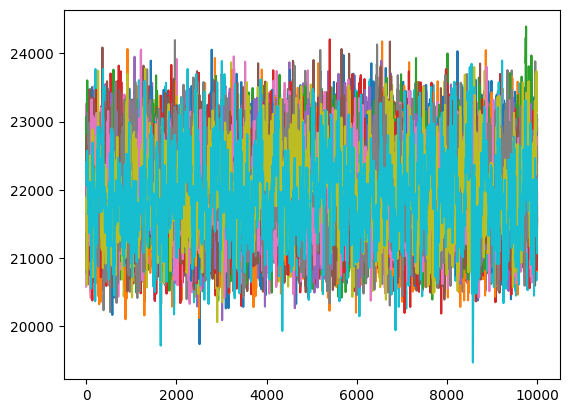

In [ ]:
import matplotlib.pyplot as plt
for i in range(0,no_of_walkers):
  a=sampler.chain[i,burn_in_steps:,0]
  l=len(a)
  n= list(range(l))
  plt.plot(n,a)

plt.show()

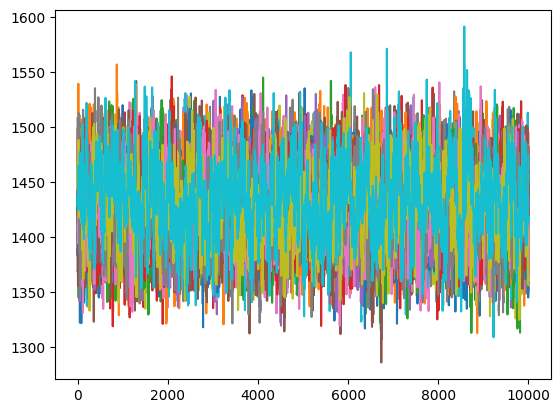

In [ ]:
#Plotting chains for value of 'Omega_lambda'
for i in range(0,no_of_walkers):
  b=sampler.chain[i,burn_in_steps:,1]
  l=len(b)
  n= list(range(l))
  plt.plot(n,b)

plt.show()

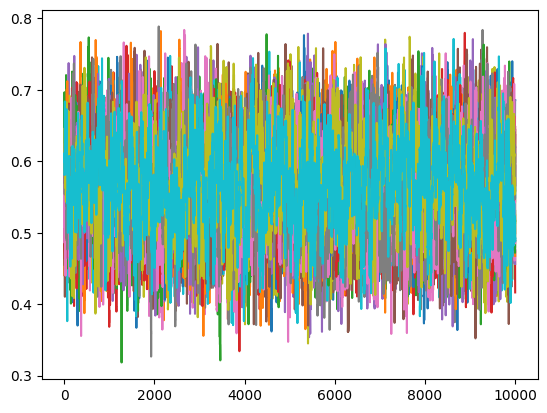

In [ ]:
for i in range(0,no_of_walkers):
  c=sampler.chain[i,burn_in_steps:,2]
  l=len(c)
  n= list(range(l))
  plt.plot(n,c)

plt.show()

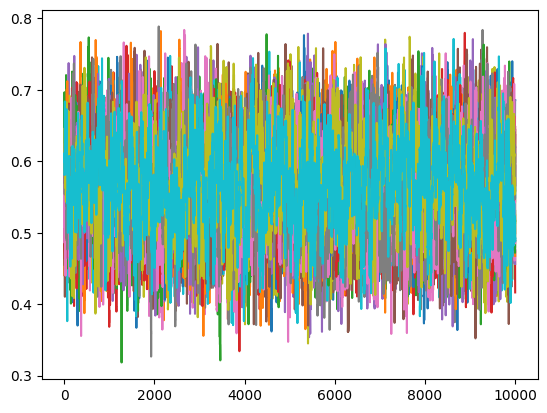

In [ ]:
for i in range(0,no_of_walkers):
  d=sampler.chain[i,burn_in_steps:,2]
  l=len(d)
  n= list(range(l))
  plt.plot(n,d)

plt.show()

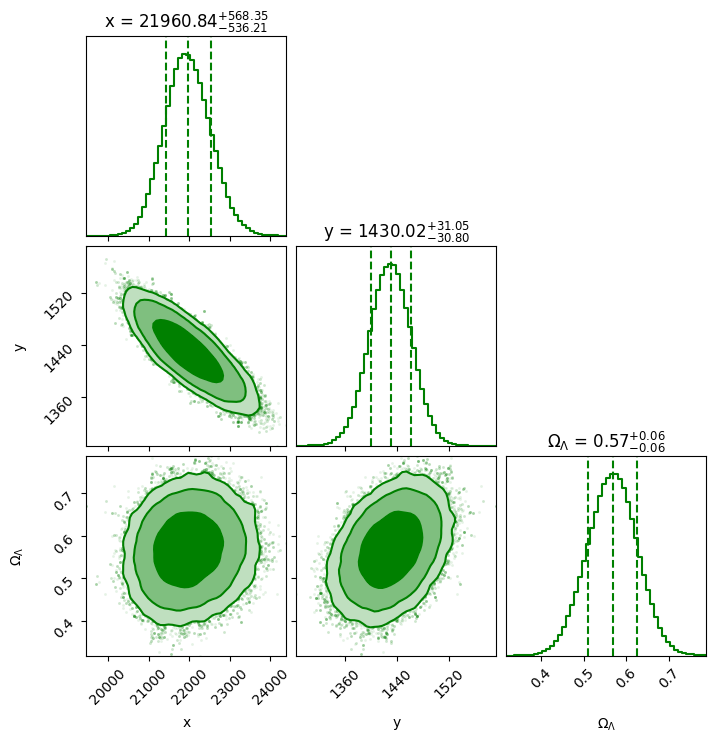

In [ ]:
import corner
samples = sampler.chain[:, burn_in_steps:, :].reshape((-1, ndimension))
fig = corner.corner(samples,bins=50,labels=["x", "y","$\Omega_{\Lambda}$","$\Omega_{\kappa}$"],
                    color="green",
                    quantiles=[0.16, 0.5, 0.84],                    #68% Confidence Error in Histogram
                    plot_contours=True,
                    fill_contours=True,
                    levels=(0.68,0.95,0.99),                        #Confidence Levels
                    plot_datapoints=True,
                    smooth=True, smooth1d=True,
                    title_fmt=".2f",
                    show_titles=True,
                    divergences=True)

plt.show()

After these optional codes (None of our use )

In [ ]:
samples = sampler.get_chain(discard=burn_in_steps, flat=True)
x_vals, y_vals, Ov_vals = samples.T
H0_vals = (x_vals * y_vals) ** 0.25
Om_vals = np.sqrt(y_vals / x_vals)
Or = 8.5e-5
Ok = -0.053
On_vals = 1 - Om_vals - Ok - Ov_vals - Or
def median_and_err(x):
    q16, q50, q84 = np.percentile(x, [16, 50, 84])
    return q50, q84 - q50, q50 - q16
H0_m, H0_p, H0_m_err = median_and_err(H0_vals)
Om_m, Om_p, Om_m_err = median_and_err(Om_vals)
On_m, On_p, On_m_err = median_and_err(On_vals)
Ov_m, Ov_p, Ov_m_err = median_and_err(Ov_vals)
x_m, x_p, x_m_err = median_and_err(x_vals)
y_m, y_p, y_m_err = median_and_err(y_vals)
print(f"H0 = {H0_m:.2f} +{H0_p:.2f} -{H0_m_err:.2f}")
print(f"Ωm = {Om_m:.3f} +{Om_p:.3f} -{Om_m_err:.3f}")
print(f"Ωn = {On_m:.3f} +{On_p:.3f} -{On_m_err:.3f}")
print(f"Ωv = {Ov_m:.3f} +{Ov_p:.3f} -{Ov_m_err:.3f}")

H0 = 74.86 +0.26 -0.26
Ωm = 0.255 +0.006 -0.006
Ωn = 0.229 +0.060 -0.057
Ωv = 0.569 +0.056 -0.059


In [ ]:
import pandas as pd
dl=DL_theory_single
DL_theory_vec = np.vectorize(DL_theory_single, excluded=['x', 'y', 'Ov', 'Ok', 'n'])
dL_model = np.array(DL_theory_vec(z=z, x=x_m, y=y_m, Ok=Ok_m, Ov=Ov_m, n=1.0))
diff=abs(dL_model-dL_data)
dict1=pd.DataFrame({"Z":z,"DL_theory": dL_model, "DL_obs": dL_data, "Difference": diff, "error in DL":dmL_data })
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)
print(dict1)